In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ch = pd.read_csv("/content/drive/MyDrive/EV Charging Infrastructure Analytics/bee_ev_clean (1).csv")
st = pd.read_csv("/content/drive/MyDrive/EV Charging Infrastructure Analytics/bee_ev_stations (1).csv")

In [ ]:

import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/EV Charging Infrastructure Analytics/bee_ev_stations (1).csv')

print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print(df.head())


Total rows: 29069
Total columns: 13
   Station_ID    CPO  Latitude  Longitude       State       District  \
0           1  Ather  8.093953  77.548708  Tamil Nadu  Kanniyakumari   
1           2  Ather  8.195771  77.442446  Tamil Nadu  Kanniyakumari   
2           3  Ather  8.237843  77.571905  Tamil Nadu    Tirunelveli   
3           4  Ather  8.278935  77.567139  Tamil Nadu    Tirunelveli   
4           5  Ather  8.348143  77.593955  Tamil Nadu    Tirunelveli   

          City Ownership  Chargers  Connectors_Dedup  Connectors_Raw  Max_kW  \
0  Kanyakumari   Private         1                 1               1     3.3   
1    NAGERCOIL   Private         1                 1               2     3.3   
2  Tirunelveli   Private         1                 1               1     3.3   
3  Tirunelveli   Private         1                 1               1     3.3   
4  Tirunelveli   Private         1                 1               1     3.3   

   Bulk_Repeat  
0        False  
1        False  

In [ ]:
print("Charger rows:", ch.shape)
print("Stations:", st.shape)

Charger rows: (31071, 19)
Stations: (29069, 13)


In [ ]:
ch.head()

,CPO,Ownership,State,District,City,Location,Latitude,Longitude,Charger_Type,Charger_Rating_kW,Connector_Rating_kW,Num_Connectors,Current_Type,Connector_Standard,Is_LEV,Power_Class,Repeat_Count,Connectors_Raw,Bulk_Repeat
0,IOCL,Govt.,Andaman & Nicobar Islands,South Andamans,South Andaman,Iocl Dealer Govind Nagar Swaraj Dweep (Haveloc...,12.034186,92.992718,Type-II AC,7.4,7.4,1,AC,Type-II AC,False,Medium (7-22 kW),1,1,False
1,IOCL,Govt.,Andaman & Nicobar Islands,South Andamans,South Andaman,Iocl Dealer S.No.45/1 Bimblitan Port Blair,11.604053,92.694109,Type-II AC,7.4,7.4,1,AC,Type-II AC,False,Medium (7-22 kW),1,1,False
2,IOCL,Govt.,Andaman & Nicobar Islands,South Andamans,South Andaman,Marina Refueling Station Vill-Austinabad Po-Br...,11.637410,92.735160,LEV AC Charge point,3.3,3.3,1,AC,LEV AC,True,Slow (<7 kW),1,1,False
3,Tata Power,Private,Andaman & Nicobar Islands,South Andamans,Port Blair,"Gennext Motors , Pahargaon, Ground Floor New, ...",11.630305,92.724835,CCS-II,25.0,25.0,1,DC,CCS-II,False,Fast (22-50 kW),1,1,False
4,Ather,Private,Andhra Pradesh,TIRUPATI,Tirupati,"27, 962, Chittoor-Bangalore Rd, Near Tvs Showr...",13.208240,79.091059,LEV DC Charge Point (IS-17017-2-7),3.3,3.3,1,DC,LEV DC,True,Slow (<7 kW),1,1,False


In [ ]:
ch.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31071 entries, 0 to 31070
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   CPO                  31071 non-null  object 
 1   Ownership            31071 non-null  object 
 2   State                31071 non-null  object 
 3   District             31071 non-null  object 
 4   City                 31068 non-null  object 
 5   Location             31071 non-null  object 
 6   Latitude             31071 non-null  float64
 7   Longitude            31071 non-null  float64
 8   Charger_Type         31071 non-null  object 
 9   Charger_Rating_kW    31071 non-null  float64
 10  Connector_Rating_kW  30886 non-null  float64
 11  Num_Connectors       31071 non-null  int64  
 12  Current_Type         31071 non-null  object 
 13  Connector_Standard   31071 non-null  object 
 14  Is_LEV               31071 non-null  bool   
 15  Power_Class          31071 non-null 

In [ ]:
ch.describe()

,Latitude,Longitude,Charger_Rating_kW,Connector_Rating_kW,Num_Connectors,Repeat_Count,Connectors_Raw
count,31071.000000,31071.000000,31071.000000,30886.000000,31071.000000,31071.000000,31071.000000
mean,20.102607,77.945723,15.698178,14.781260,1.136043,1.272054,1.414470
std,6.531529,4.162049,23.155958,21.411064,0.360682,3.245096,3.263902
min,8.092951,68.940700,1.100000,1.100000,1.000000,1.000000,1.000000
25%,13.043286,75.571151,3.300000,3.300000,1.000000,1.000000,1.000000
50%,19.279281,77.421840,3.300000,3.300000,1.000000,1.000000,1.000000
75%,26.206246,78.787800,15.000000,15.000000,1.000000,1.000000,1.000000
max,34.558845,96.158969,142.000000,120.000000,3.000000,198.000000,198.000000


In [ ]:
miss = ch.isna().sum()
print(pd.DataFrame({"missing": miss, "%": (miss / len(ch) * 100).round(2)}).query("missing > 0"))

                     missing     %
City                       3  0.01
Connector_Rating_kW      185  0.60


In [ ]:
print("Exact duplicate rows:", ch.duplicated().sum())

print("Rows with Repeat_Count > 1:",
      (ch["Repeat_Count"] > 1).sum())

print("Total Repeat_Count:",
      ch["Repeat_Count"].sum())

print("Highest Repeat_Count:",
      ch["Repeat_Count"].max())

Exact duplicate rows: 0
Rows with Repeat_Count > 1: 2982
Total Repeat_Count: 39524
Highest Repeat_Count: 198


In [ ]:
print("Total cleaned charger rows:", len(ch))
print("Rows with Repeat_Count = 1:",
      (ch["Repeat_Count"] == 1).sum())
print("Rows with Repeat_Count > 1:",
      (ch["Repeat_Count"] > 1).sum())

print("\nRepeat count distribution:")
print(ch["Repeat_Count"].value_counts().sort_index().head(20))

print("\nHighest repeat-count records:")
print(
    ch.nlargest(10, "Repeat_Count")[
        ["CPO", "State", "District", "City", "Repeat_Count"]
    ]
)

Total cleaned charger rows: 31071
Rows with Repeat_Count = 1: 28089
Rows with Repeat_Count > 1: 2982

Repeat count distribution:
Repeat_Count
1     28089
2      1982
3       552
4       136
5        40
6       144
7         5
8        11
9        26
10        7
11        2
12        8
14        1
15        1
16        4
18        5
20        7
22        2
23        1
24        7
Name: count, dtype: int64

Highest repeat-count records:
              CPO      State         District       City  Repeat_Count
6275  Reliance BP    Haryana         Gurugram   Gurugram           198
6242  Reliance BP    Haryana        Faridabad  Faridabad           180
6246  Reliance BP    Haryana        Faridabad  Faridabad           141
9080  Reliance BP  Karnataka  Bengaluru Urban  Bengaluru           141
9112  Reliance BP  Karnataka  Bengaluru Urban  Bengaluru           129
6250  Reliance BP    Haryana         Gurugram   Gurugram           123
9063  Reliance BP  Karnataka  Bengaluru Urban  Bengaluru        

In [ ]:
print("Sum of Repeat_Count:", ch["Repeat_Count"].sum())

print("Repeated rows:", (ch["Repeat_Count"] > 1).sum())

print("Extra occurrences beyond one per row:",
      (ch["Repeat_Count"] - 1).sum())

print("Total extra occurrences among repeated rows:",
      ch.loc[ch["Repeat_Count"] > 1, "Repeat_Count"].sub(1).sum())

Sum of Repeat_Count: 39524
Repeated rows: 2982
Extra occurrences beyond one per row: 8453
Total extra occurrences among repeated rows: 8453


In [ ]:
def bar(series, title, top=10):
    s = series.value_counts().head(top)
    s.sort_values().plot(kind="barh", color="#2a7f62")
    plt.title(title); plt.xlabel("count"); plt.tight_layout(); plt.show()
    print(s)

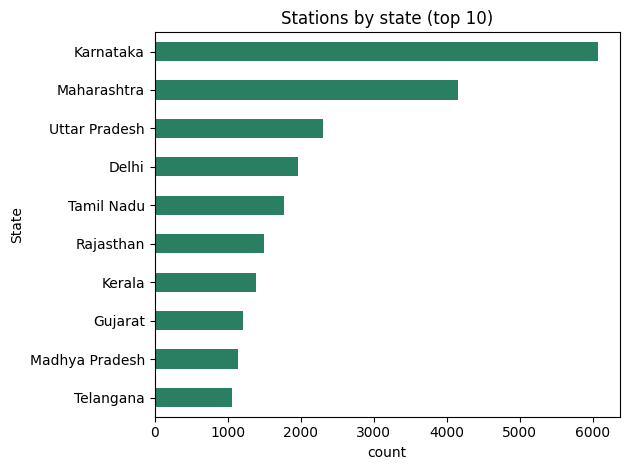

State
Karnataka         6069
Maharashtra       4159
Uttar Pradesh     2305
Delhi             1966
Tamil Nadu        1776
Rajasthan         1505
Kerala            1393
Gujarat           1206
Madhya Pradesh    1141
Telangana         1054
Name: count, dtype: int64


In [ ]:
bar(st["State"], "Stations by state (top 10)")

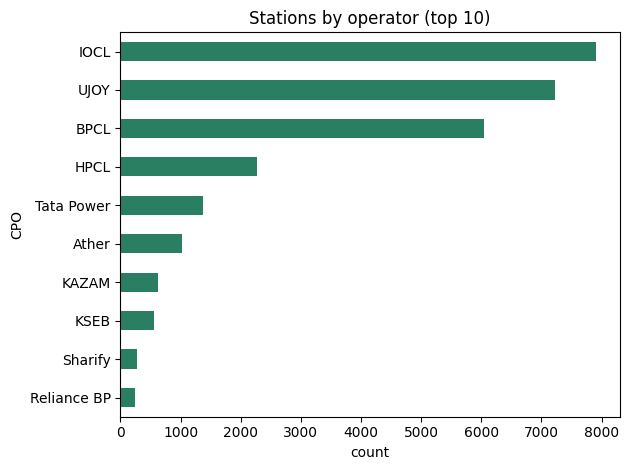

CPO
IOCL           7912
UJOY           7220
BPCL           6052
HPCL           2264
Tata Power     1369
Ather          1020
KAZAM           618
KSEB            555
Sharify         277
Reliance BP     245
Name: count, dtype: int64


In [ ]:
bar(st["CPO"], "Stations by operator (top 10)")

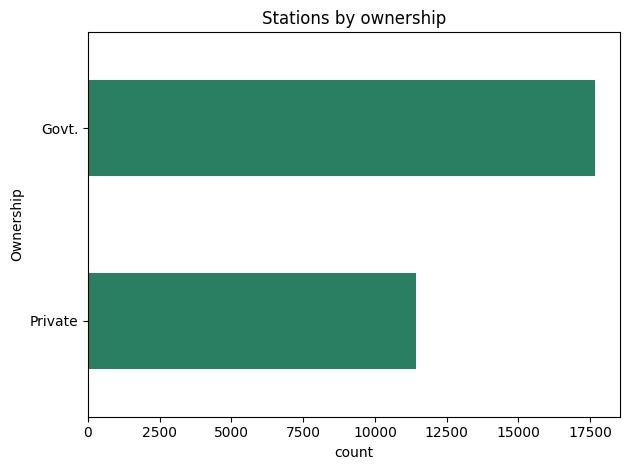

Ownership
Govt.      17655
Private    11414
Name: count, dtype: int64


In [ ]:
bar(st["Ownership"], "Stations by ownership", top=5)

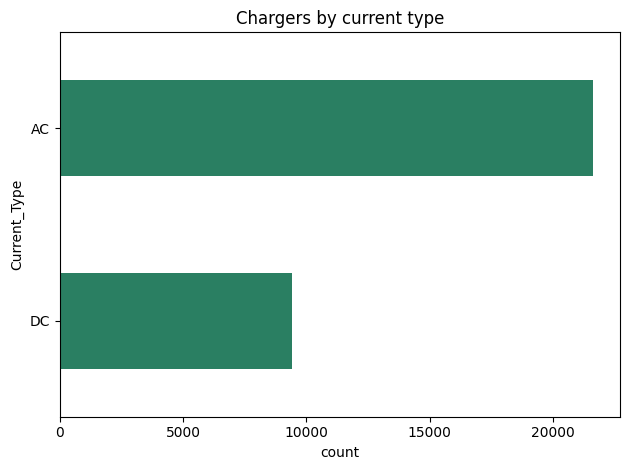

Current_Type
AC    21640
DC     9431
Name: count, dtype: int64


In [ ]:
bar(ch["Current_Type"], "Chargers by current type", top=5)

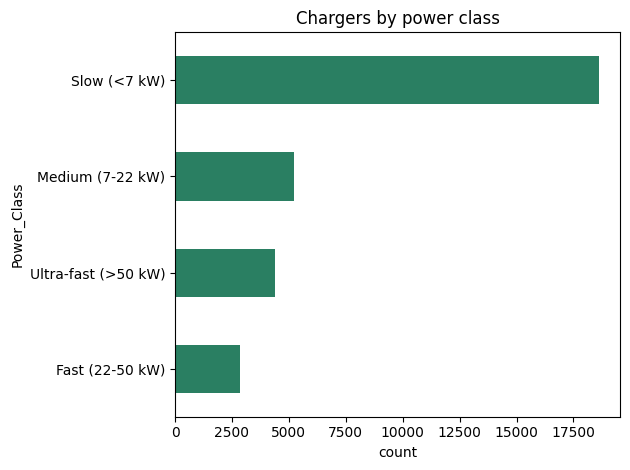

Power_Class
Slow (<7 kW)           18614
Medium (7-22 kW)        5213
Ultra-fast (>50 kW)     4376
Fast (22-50 kW)         2868
Name: count, dtype: int64


In [ ]:
bar(ch["Power_Class"], "Chargers by power class", top=5)

In [ ]:
print(pd.crosstab(
    ch["Is_LEV"],
    ch["Power_Class"],
    normalize="index"
).mul(100).round(1))

Power_Class  Fast (22-50 kW)  Medium (7-22 kW)  Slow (<7 kW)  \
Is_LEV                                                         
False                   17.6              30.5          24.9   
True                     0.0               1.7          98.3   

Power_Class  Ultra-fast (>50 kW)  
Is_LEV                            
False                       26.9  
True                         0.0  


In [ ]:
print((pd.crosstab(ch["Ownership"], ch["Current_Type"], normalize="index") * 100).round(1))

Current_Type    AC    DC
Ownership               
Govt.         66.5  33.5
Private       74.3  25.7


In [ ]:
q1, q3 = ch["Charger_Rating_kW"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = ch[(ch["Charger_Rating_kW"] < low) | (ch["Charger_Rating_kW"] > high)]
print("Normal range (kW):", low, "to", high)
print("Outlier rows:", len(out), "(", round(len(out) / len(ch) * 100, 1), "% )")
print(out["Charger_Rating_kW"].value_counts().head())

Normal range (kW): -14.249999999999996 to 32.55
Outlier rows: 4584 ( 14.8 % )
Charger_Rating_kW
60.0     3950
120.0     243
50.0      208
142.0      92
122.0      75
Name: count, dtype: int64


In [ ]:
s = st["State"].value_counts()
c = st["City"].value_counts()
print("Top 5 states hold", round(s.head(5).sum() / len(st) * 100, 1), "% of stations")
print("Top 10 cities hold", round(c.head(10).sum() / len(st) * 100, 1), "% of stations")
print(c.head(10))
dist = st.groupby(["State", "District"]).size()
print("Districts:", len(dist), "| with only 1 station:", (dist == 1).sum(), "| median stations per district:", dist.median())
print("\nStates with fewest stations:"); print(s.tail(8))

Top 5 states hold 56.0 % of stations
Top 10 cities hold 33.5 % of stations
City
Bengaluru    4245
Delhi        1965
Pune         1907
Mumbai        457
Chennai       265
Hyderabad     224
Bangalore     217
Ahmedabad     193
Jaipur        138
Gurugram      127
Name: count, dtype: int64
Districts: 776 | with only 1 station: 35 | median stations per district: 18.0

States with fewest stations:
State
Nagaland                                42
Chandigarh                              14
Mizoram                                 13
Sikkim                                  12
Dadra & Nagar Haveli and Daman & Diu     9
Andaman & Nicobar Islands                4
Ladakh                                   1
Lakshadweep                              1
Name: count, dtype: int64


In [ ]:
for t in (ch, st):
    t["City"] = t["City"].replace({"Bangalore": "Bengaluru"})
print(st["City"].value_counts().head(10))

City
Bengaluru    4462
Delhi        1965
Pune         1907
Mumbai        457
Chennai       265
Hyderabad     224
Ahmedabad     193
Jaipur        138
Gurugram      127
Nashik        126
Name: count, dtype: int64


In [ ]:
st.to_csv("bee_ev_stations.csv", index=False)
ch.to_csv("bee_ev_clean.csv", index=False)
from google.colab import files
files.download("bee_ev_stations.csv"); files.download("bee_ev_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
rc = ch["Repeat_Count"]
print("Cleaned rows:", len(ch))
print("Repeat_Count = 1:", (rc == 1).sum())
print("Repeat_Count > 1:", (rc > 1).sum())
print("Sum of Repeat_Count:", rc.sum())
print("Extra occurrences:", rc.sum() - len(ch))
print("Highest:", rc.max())
ok = ch["Latitude"].between(6, 37.5) & ch["Longitude"].between(68, 98)
print("All cleaned rows inside India bounds:", ok.all())

Cleaned rows: 31071
Repeat_Count = 1: 28089
Repeat_Count > 1: 2982
Sum of Repeat_Count: 39524
Extra occurrences: 8453
Highest: 198
All cleaned rows inside India bounds: True


In [ ]:

import pandas as pd

ch = pd.read_csv("bee_ev_clean.csv")
st = pd.read_csv("bee_ev_stations.csv")

print("=== SAVED FILE VERIFICATION ===")
print("Charger rows:", len(ch))
print("Station rows:", len(st))

print("\n=== REPEAT COUNT VERIFICATION ===")
print("Repeat_Count total:", ch["Repeat_Count"].sum())
print("Rows with Repeat_Count > 1:", (ch["Repeat_Count"] > 1).sum())
print("Rows with Repeat_Count = 1:", (ch["Repeat_Count"] == 1).sum())
print("Exact duplicate rows remaining:", ch.duplicated().sum())

print("\n=== COORDINATE COLUMNS ===")
print(ch.columns.tolist())


=== SAVED FILE VERIFICATION ===
Charger rows: 31071
Station rows: 29069

=== REPEAT COUNT VERIFICATION ===
Repeat_Count total: 39524
Rows with Repeat_Count > 1: 2982
Rows with Repeat_Count = 1: 28089
Exact duplicate rows remaining: 0

=== COORDINATE COLUMNS ===
['CPO', 'Ownership', 'State', 'District', 'City', 'Location', 'Latitude', 'Longitude', 'Charger_Type', 'Charger_Rating_kW', 'Connector_Rating_kW', 'Num_Connectors', 'Current_Type', 'Connector_Standard', 'Is_LEV', 'Power_Class', 'Repeat_Count', 'Connectors_Raw', 'Bulk_Repeat']


In [ ]:
w = ch["Repeat_Count"]
print((ch.groupby("Current_Type")["Repeat_Count"].sum() / w.sum() * 100).round(1))
print((ch.groupby("Power_Class")["Repeat_Count"].sum() / w.sum() * 100).round(1))

Current_Type
AC    69.6
DC    30.4
Name: Repeat_Count, dtype: float64
Power_Class
Fast (22-50 kW)         8.9
Medium (7-22 kW)       21.0
Slow (<7 kW)           56.5
Ultra-fast (>50 kW)    13.6
Name: Repeat_Count, dtype: float64
